### 加载数据

In [1]:
import numpy as np
import pandas as pd
data = pd.read_excel('./中国人寿.xlsx')
print(data.shape)
data.head()

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### EDA数据探索

<AxesSubplot:xlabel='charges', ylabel='Density'>

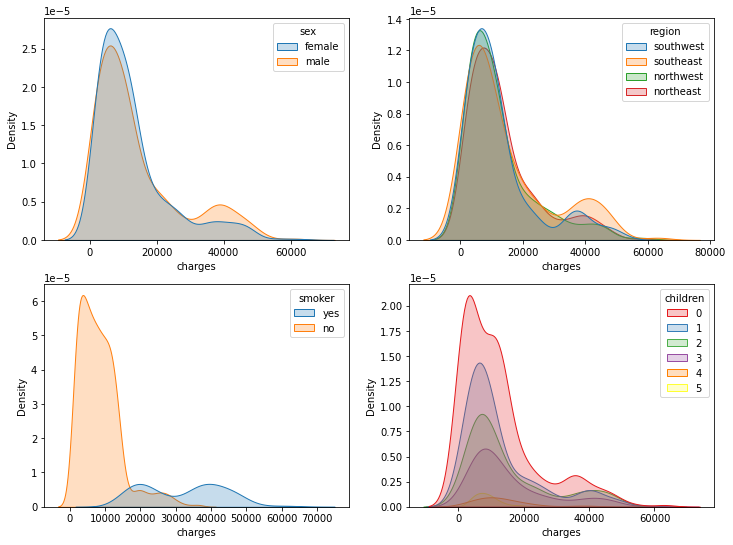

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
fig,axes = plt.subplots(2,2,figsize = (12,9))

# 性别对保费影响
sns.kdeplot(data['charges'],shade = True,hue = data['sex'],ax = axes[0,0])

# 地区对保费影响
sns.kdeplot(data['charges'],shade = True,hue = data['region'],ax = axes[0,1])

# 吸烟对保费影响
sns.kdeplot(data['charges'],shade = True,hue = data['smoker'],ax = axes[1,0])

# 孩子数量对保费影响
sns.kdeplot(data['charges'],shade = True,hue = data['children'],palette='Set1',ax = axes[1,1])

### 特征工程

#### 删除不重要特征

In [4]:
data = data.drop(['region', 'sex'], axis=1)
data.head() # 删除不重要特征

,age,bmi,children,smoker,charges
0,19,27.900,0,yes,16884.92400
1,18,33.770,1,no,1725.55230
2,28,33.000,3,no,4449.46200
3,33,22.705,0,no,21984.47061
4,32,28.880,0,no,3866.85520


#### 体重数据转换

In [5]:
# 体重指数，离散化转换，体重两种情况：标准、肥胖
def convert(df,bmi):
    df['bmi'] = 'fat' if df['bmi'] >= bmi else 'standard'
    return df
data = data.apply(convert, axis = 1, args=(30,))
data.head()

,age,bmi,children,smoker,charges
0,19,standard,0,yes,16884.92400
1,18,fat,1,no,1725.55230
2,28,fat,3,no,4449.46200
3,33,standard,0,no,21984.47061
4,32,standard,0,no,3866.85520


#### 字符串独热编码数据转换

In [6]:
# 特征提取，离散型数据转换为数值型数据
data = pd.get_dummies(data)
data.head()

,age,children,charges,bmi_fat,bmi_standard,smoker_no,smoker_yes
0,19,0,16884.92400,0,1,0,1
1,18,1,1725.55230,1,0,1,0
2,28,3,4449.46200,1,0,1,0
3,33,0,21984.47061,0,1,1,0
4,32,0,3866.85520,0,1,1,0


#### 数据提取

In [7]:
# 特征和目标值抽取
X = data.drop('charges', axis=1) # 训练数据
y = data['charges'] # 目标值
X.head()

,age,children,bmi_fat,bmi_standard,smoker_no,smoker_yes
0,19,0,0,1,0,1
1,18,1,1,0,1,0
2,28,3,1,0,1,0
3,33,0,0,1,1,0
4,32,0,0,1,1,0


#### 数据升维(对比)

In [17]:
from sklearn.preprocessing import PolynomialFeatures
# 特征升维
poly = PolynomialFeatures(degree= 2,interaction_only=True, include_bias = False)
X = poly.fit_transform(X)
X

array([[19.,  0.,  0., ...,  0.,  1.,  0.],
       [18.,  1.,  1., ...,  0.,  0.,  0.],
       [28.,  3.,  1., ...,  0.,  0.,  0.],
       ...,
       [18.,  0.,  1., ...,  0.,  0.,  0.],
       [21.,  0.,  0., ...,  1.,  0.,  0.],
       [61.,  0.,  0., ...,  0.,  1.,  0.]])

In [22]:
poly = PolynomialFeatures(degree= 2,interaction_only=False, include_bias = False)
poly.fit_transform([[2,3]])

array([[2., 3., 4., 6., 9.]])

In [18]:
X.shape

(1338, 21)

#### 数据拆分

In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=1024)

### 模型训练与评估

#### 线性回归

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_squared_log_error

# 训练
model_1 = LinearRegression()
model_1.fit(X_train, y_train)

# 评估R_2评估
print('测试数据得分：',model_1.score(X_train,y_train))
print('预测数据得分：',model_1.score(X_test,y_test))

# 均方误差
print('训练数据均方误差：',np.sqrt(mean_squared_error(y_train, model_1.predict(X_train))))
print('测试数据均方误差：',np.sqrt(mean_squared_error(y_test, model_1.predict(X_test))))

# 均方误差求对数
print('训练数据对数误差：',np.sqrt(mean_squared_log_error(y_train,model_1.predict(X_train))))
print('测试数据对数误差：',np.sqrt(mean_squared_log_error(y_test,model_1.predict(X_test))))

测试数据得分： 0.7535598431225087
预测数据得分： 0.7509918136220449
训练数据均方误差： 6059.148631223071
测试数据均方误差： 5834.794551018322
训练数据对数误差： 0.6817657584831845
测试数据对数误差： 0.6742650494561568


In [24]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_squared_log_error

# 训练
model_1 = LinearRegression()
model_1.fit(X_train, y_train)

# 评估R_2评估
print('测试数据得分：',model_1.score(X_train,y_train))
print('预测数据得分：',model_1.score(X_test,y_test))

# 均方误差
print('训练数据均方误差：',np.sqrt(mean_squared_error(y_train, model_1.predict(X_train))))
print('测试数据均方误差：',np.sqrt(mean_squared_error(y_test, model_1.predict(X_test))))

# 均方误差求对数
print('训练数据对数误差：',np.sqrt(mean_squared_log_error(y_train,model_1.predict(X_train))))
print('测试数据对数误差：',np.sqrt(mean_squared_log_error(y_test,model_1.predict(X_test))))

测试数据得分： 0.8596043357275309
预测数据得分： 0.8683731092655589
训练数据均方误差： 4573.331848173892
测试数据均方误差： 4242.199294652197
训练数据对数误差： 0.40266523355137473
测试数据对数误差： 0.37384656097345675


#### 弹性网络

In [16]:
from sklearn.linear_model import ElasticNet

model_2 = ElasticNet(alpha =0.01,l1_ratio = 0.1,max_iter = 50000)
model_2.fit(X_train,y_train)

print('测试数据得分：',model_2.score(X_train,y_train))
print('预测数据得分：',model_2.score(X_test,y_test))

print('训练数据均方误差为：',np.sqrt(mean_squared_error(y_train,model_2.predict(X_train))))
print('测试数据均方误差为：',np.sqrt(mean_squared_error(y_test,model_2.predict(X_test))))

print('训练数据对数误差为：',np.sqrt(mean_squared_log_error(y_train,model_2.predict(X_train))))
print('测试数据对数误差为：',np.sqrt(mean_squared_log_error(y_test,model_2.predict(X_test))))

测试数据得分： 0.7531070282334128
预测数据得分： 0.7508706619655365
训练数据均方误差为： 6064.712686985539
测试数据均方误差为： 5836.2137996659585
训练数据对数误差为： 0.59938077986831
测试数据对数误差为： 0.5893459793184204


In [25]:
from sklearn.linear_model import ElasticNet

model_2 = ElasticNet(alpha =0.01,l1_ratio = 0.1,max_iter = 50000)
model_2.fit(X_train,y_train)

print('测试数据得分：',model_2.score(X_train,y_train))
print('预测数据得分：',model_2.score(X_test,y_test))

print('训练数据均方误差为：',np.sqrt(mean_squared_error(y_train,model_2.predict(X_train))))
print('测试数据均方误差为：',np.sqrt(mean_squared_error(y_test,model_2.predict(X_test))))

print('训练数据对数误差为：',np.sqrt(mean_squared_log_error(y_train,model_2.predict(X_train))))
print('测试数据对数误差为：',np.sqrt(mean_squared_log_error(y_test,model_2.predict(X_test))))

测试数据得分： 0.8577141727865707
预测数据得分： 0.8649658876399435
训练数据均方误差为： 4604.014567968173
测试数据均方误差为： 4296.754130211094
训练数据对数误差为： 0.4202325205972563
测试数据对数误差为： 0.3955443048336467


c:\python38\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:530: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 12227282004.250319, tolerance: 15940264.112170765
  model = cd_fast.enet_coordinate_descent(
